<a href="https://colab.research.google.com/github/Kavikar29003/credit-risk-validation/blob/main/01_data_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os, getpass
os.environ["KGAT_bc3221da7167f9aaa168a77f275194d9"] = getpass.getpass("Paste your Kaggle token: ")

Paste your Kaggle token: ··········


In [2]:
!pip install -q --upgrade kaggle
!kaggle competitions download -c home-credit-default-risk -f application_train.csv
!kaggle competitions download -c home-credit-default-risk -f bureau.csv
!for f in *.zip; do unzip -o "$f"; done

Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token
Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, gener

In [5]:
!ls -l application_train.csv bureau.csv
!wc -l application_train.csv

-rw-r--r-- 1 root root 166133370 Oct 30 04:03 application_train.csv
-rw-r--r-- 1 root root 170016717 Oct 30 04:03 bureau.csv
307512 application_train.csv


In [10]:
import numpy as np, pandas as pd

app = pd.read_csv("application_train.csv")
bureau = pd.read_csv("bureau.csv")
n0 = len(app)
print("application:", app.shape, "| bureau:", bureau.shape)

# 1. Who carries the 365243 placeholder?
bad = app["DAYS_EMPLOYED"] == 365243
print("\nPlaceholder rows by income type:")
print(app.loc[bad, "NAME_INCOME_TYPE"].value_counts())
print("\nOther rows by income type (top 6):")
print(app.loc[~bad, "NAME_INCOME_TYPE"].value_counts().head(6))

# 2. Cleaning
app["DAYS_EMPLOYED_PLACEHOLDER"] = bad.astype(int)
app.loc[bad, "DAYS_EMPLOYED"] = np.nan
app["AGE_YEARS"] = -app["DAYS_BIRTH"] / 365.25
app["EMPLOYED_YEARS"] = -app["DAYS_EMPLOYED"] / 365.25
app = app.drop(columns=["DAYS_BIRTH", "DAYS_EMPLOYED"])
for c in ["CODE_GENDER", "ORGANIZATION_TYPE"]:
    app[c] = app[c].replace("XNA", np.nan)

# ratios first, then log-transform the skewed money columns
app["CREDIT_INCOME_RATIO"] = app["AMT_CREDIT"] / app["AMT_INCOME_TOTAL"]
app["ANNUITY_INCOME_RATIO"] = app["AMT_ANNUITY"] / app["AMT_INCOME_TOTAL"]
for c in ["AMT_INCOME_TOTAL", "AMT_CREDIT", "AMT_ANNUITY", "AMT_GOODS_PRICE"]:
    app[c] = np.log1p(app[c])

# 3. Bureau: one row per applicant
b = bureau.copy()
b["IS_ACTIVE"] = (b["CREDIT_ACTIVE"] == "Active").astype(int)
b["HAS_OVERDUE"] = (b["CREDIT_DAY_OVERDUE"] > 0).astype(int)
agg = b.groupby("SK_ID_CURR").agg(
    BUREAU_N_LOANS=("SK_ID_BUREAU", "count"),
    BUREAU_N_ACTIVE=("IS_ACTIVE", "sum"),
    BUREAU_N_OVERDUE=("HAS_OVERDUE", "sum"),
    BUREAU_MAX_OVERDUE_DAYS=("CREDIT_DAY_OVERDUE", "max"),
    BUREAU_CREDIT_SUM_MEAN=("AMT_CREDIT_SUM", "mean"),
    BUREAU_DEBT_SUM=("AMT_CREDIT_SUM_DEBT", "sum"),
    BUREAU_DAYS_CREDIT_MEAN=("DAYS_CREDIT", "mean"),
).reset_index()

app = app.merge(agg, on="SK_ID_CURR", how="left")
assert len(app) == n0 and app["SK_ID_CURR"].is_unique, "join duplicated rows"
app["HAS_BUREAU"] = app["BUREAU_N_LOANS"].notna().astype(int)
for c in ["BUREAU_N_LOANS", "BUREAU_N_ACTIVE", "BUREAU_N_OVERDUE"]:
    app[c] = app[c].fillna(0)
print("\nApplicants with no bureau record:", (app["HAS_BUREAU"] == 0).sum())
print(app.groupby("HAS_BUREAU")["TARGET"].agg(["mean", "count"]))

# 4. Drop columns that are more than 50% missing
miss = app.isna().mean()
drop = miss[miss > 0.5].index.tolist()
print("\nDropping", len(drop), "columns with >50% missing")
app = app.drop(columns=drop)
print("Final shape:", app.shape)
app.to_parquet("clean.parquet")

application: (307511, 122) | bureau: (1716428, 17)

Placeholder rows by income type:
NAME_INCOME_TYPE
Pensioner     55352
Unemployed       22
Name: count, dtype: int64

Other rows by income type (top 6):
NAME_INCOME_TYPE
Working                 158774
Commercial associate     71617
State servant            21703
Student                     18
Pensioner                   10
Businessman                 10
Name: count, dtype: int64

Applicants with no bureau record: 44020
                mean   count
HAS_BUREAU                  
0           0.101249   44020
1           0.077301  263491

Dropping 41 columns with >50% missing
Final shape: (307511, 92)


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

y = app["TARGET"].values
X = app.drop(columns=["TARGET", "SK_ID_CURR"])
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_cal, X_te, y_cal, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
print("split sizes:", len(y_tr), len(y_cal), len(y_te))
print("default rate:", y_tr.mean().round(4), y_cal.mean().round(4), y_te.mean().round(4))

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("numeric cols:", len(num_cols), "| categorical cols:", len(cat_cols))

pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="missing")),
                      ("oh", OneHotEncoder(handle_unknown="ignore", min_frequency=100,
                                           sparse_output=False))]), cat_cols),
])

# fit on train only, so nothing leaks from calibration or test
Xt_tr = pre.fit_transform(X_tr).astype(np.float32)
Xt_cal = pre.transform(X_cal).astype(np.float32)
Xt_te = pre.transform(X_te).astype(np.float32)
feat_names = pre.get_feature_names_out()
print("matrix shape:", Xt_tr.shape, "| NaNs left:", int(np.isnan(Xt_tr).sum()))
np.savez_compressed("processed.npz", Xt_tr=Xt_tr, Xt_cal=Xt_cal, Xt_te=Xt_te,
                    y_tr=y_tr, y_cal=y_cal, y_te=y_te)

split sizes: 184506 61502 61503
default rate: 0.0807 0.0807 0.0807
numeric cols: 77 | categorical cols: 13
matrix shape: (184506, 197) | NaNs left: 0


logistic regression fitted in 10 s, iterations: [53]
xgboost fitted in 33 s

TEST SET RESULTS
                model    AUC  log_loss  brier    ECE
constant (prevalence) 0.5000    0.2805 0.0742 0.0023
  logistic regression 0.7540    0.2476 0.0681 0.0026
              xgboost 0.7613    0.2450 0.0675 0.0034
accuracy of 'nobody defaults': 0.9193

Reliability, logistic regression (10 equal-count bins)
 mean_predicted  observed_rate      n
         0.0128         0.0140 6151.0
         0.0222         0.0213 6151.0
         0.0304         0.0254 6151.0
         0.0393         0.0354 6150.0
         0.0496         0.0476 6150.0
         0.0622         0.0662 6150.0
         0.0791         0.0803 6150.0
         0.1036         0.1047 6150.0
         0.1440         0.1454 6150.0
         0.2617         0.2670 6150.0

Reliability, xgboost (10 equal-count bins)
 mean_predicted  observed_rate      n
         0.0136         0.0127 6151.0
         0.0224         0.0169 6151.0
         0.0300         

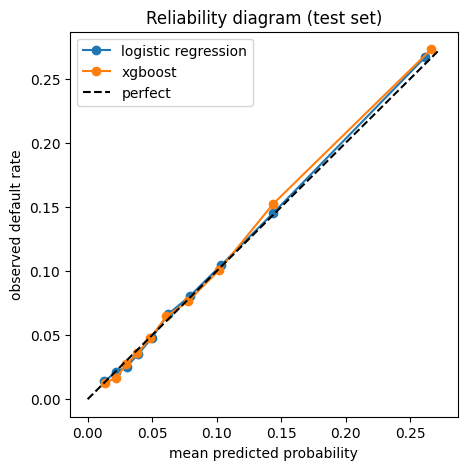


LR most negative coefficients:
 num__AMT_GOODS_PRICE                   -1.113
cat__CODE_GENDER_F                     -0.475
cat__ORGANIZATION_TYPE_Military        -0.471
num__EXT_SOURCE_3                      -0.435
cat__FLAG_OWN_CAR_Y                    -0.425
cat__NAME_CONTRACT_TYPE_Cash loans     -0.414
num__EXT_SOURCE_2                      -0.388
cat__ORGANIZATION_TYPE_Trade: type 2   -0.382
dtype: float64

LR most positive coefficients:
 num__FLAG_DOCUMENT_3                        0.180
cat__ORGANIZATION_TYPE_Industry: type 1     0.185
num__BUREAU_N_ACTIVE                        0.201
cat__ORGANIZATION_TYPE_Construction         0.260
cat__ORGANIZATION_TYPE_Realtor              0.272
cat__OCCUPATION_TYPE_Low-skill Laborers     0.278
cat__ORGANIZATION_TYPE_Transport: type 3    0.496
num__AMT_CREDIT                             1.272
dtype: float64

XGBoost top 10 features:
 num__EXT_SOURCE_3                                         0.0560
num__EXT_SOURCE_2                           

In [12]:
import time, matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, log_loss, brier_score_loss

t = time.time()
lr = LogisticRegression(C=1.0, max_iter=2000)
lr.fit(Xt_tr, y_tr)
print("logistic regression fitted in", round(time.time() - t), "s, iterations:", lr.n_iter_)

t = time.time()
xgb = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                    colsample_bytree=0.8, min_child_weight=5, tree_method="hist",
                    n_jobs=-1, random_state=42, eval_metric="logloss")
xgb.fit(Xt_tr, y_tr)
print("xgboost fitted in", round(time.time() - t), "s")

def ece_quantile(y, p, n_bins=10):
    o = np.argsort(p); y, p = y[o], p[o]
    return sum(len(i) / len(p) * abs(p[i].mean() - y[i].mean())
               for i in np.array_split(np.arange(len(p)), n_bins))

def reliability(y, p, n_bins=10):
    o = np.argsort(p); y, p = y[o], p[o]
    return np.array([[p[i].mean(), y[i].mean(), len(i)] for i in np.array_split(np.arange(len(p)), n_bins)])

p_const = np.full(len(y_te), y_tr.mean())
preds = {"constant (prevalence)": p_const,
         "logistic regression": lr.predict_proba(Xt_te)[:, 1],
         "xgboost": xgb.predict_proba(Xt_te)[:, 1]}

rows = []
for name, p in preds.items():
    rows.append([name, roc_auc_score(y_te, p), log_loss(y_te, p),
                 brier_score_loss(y_te, p), ece_quantile(y_te, p)])
res = pd.DataFrame(rows, columns=["model", "AUC", "log_loss", "brier", "ECE"]).round(4)
print("\nTEST SET RESULTS")
print(res.to_string(index=False))
print("accuracy of 'nobody defaults':", round((y_te == 0).mean(), 4))

for name in ["logistic regression", "xgboost"]:
    r = reliability(y_te, preds[name])
    print("\nReliability,", name, "(10 equal-count bins)")
    print(pd.DataFrame(r, columns=["mean_predicted", "observed_rate", "n"]).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 5))
m = 0.0
for name in ["logistic regression", "xgboost"]:
    r = reliability(y_te, preds[name]); m = max(m, r[:, 0].max(), r[:, 1].max())
    ax.plot(r[:, 0], r[:, 1], "o-", label=name)
ax.plot([0, m], [0, m], "k--", label="perfect")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed default rate")
ax.legend(); ax.set_title("Reliability diagram (test set)")
plt.savefig("reliability_baseline.png", dpi=150, bbox_inches="tight"); plt.show()

coef = pd.Series(lr.coef_[0], index=feat_names).sort_values()
print("\nLR most negative coefficients:\n", coef.head(8).round(3))
print("\nLR most positive coefficients:\n", coef.tail(8).round(3))
imp = pd.Series(xgb.feature_importances_, index=feat_names).sort_values(ascending=False)
print("\nXGBoost top 10 features:\n", imp.head(10).round(4))

corr(AMT_CREDIT, AMT_GOODS_PRICE): 0.9882
smallest eigenvalues: [-3.17296224e-15 -3.02689043e-16 -2.09319925e-16 -1.42446072e-16
 -6.72950511e-17]
largest eigenvalue: 6.35
numerical rank: 183 of 197

SUBGROUP CALIBRATION
                group model     n  observed  mean_pred    AUC
             gender F    LR 40345    0.0696     0.0701 0.7492
             gender F   XGB 40345    0.0696     0.0706 0.7558
             gender M    LR 21158    0.1020     0.1003 0.7472
             gender M   XGB 21158    0.1020     0.0991 0.7563
pensioner placeholder    LR 11028    0.0524     0.0547 0.7200
pensioner placeholder   XGB 11028    0.0524     0.0536 0.7308
     no bureau record    LR  8935    0.0989     0.1029 0.7213
     no bureau record   XGB  8935    0.0989     0.1018 0.7365
    has bureau record    LR 52568    0.0776     0.0767 0.7590
    has bureau record   XGB 52568    0.0776     0.0767 0.7646

Platt parameters (slope, intercept): 0.978 -2.432

CLASS WEIGHTING EXPERIMENT (test set; true de

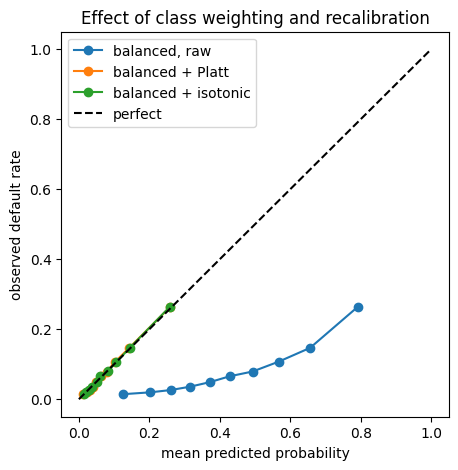

In [13]:
from sklearn.isotonic import IsotonicRegression

# 1. Collinearity: how singular is X'X?
fn = list(feat_names)
i_c, i_g = fn.index("num__AMT_CREDIT"), fn.index("num__AMT_GOODS_PRICE")
print("corr(AMT_CREDIT, AMT_GOODS_PRICE):", np.corrcoef(Xt_tr[:, i_c], Xt_tr[:, i_g])[0, 1].round(4))
Xd = Xt_tr.astype(np.float64)
G = Xd.T @ Xd / len(Xd)
ev = np.linalg.eigvalsh(G)
print("smallest eigenvalues:", ev[:5])
print("largest eigenvalue:", ev[-1].round(2))
print("numerical rank:", np.linalg.matrix_rank(G), "of", G.shape[0])

# 2. Subgroup calibration (test set)
groups = {
    "gender F": (X_te["CODE_GENDER"] == "F").values,
    "gender M": (X_te["CODE_GENDER"] == "M").values,
    "pensioner placeholder": (X_te["DAYS_EMPLOYED_PLACEHOLDER"] == 1).values,
    "no bureau record": (X_te["HAS_BUREAU"] == 0).values,
    "has bureau record": (X_te["HAS_BUREAU"] == 1).values,
}
rows = []
for g, m in groups.items():
    for name, p in [("LR", preds["logistic regression"]), ("XGB", preds["xgboost"])]:
        rows.append([g, name, int(m.sum()), y_te[m].mean(), p[m].mean(), roc_auc_score(y_te[m], p[m])])
print("\nSUBGROUP CALIBRATION")
print(pd.DataFrame(rows, columns=["group", "model", "n", "observed", "mean_pred", "AUC"]).round(4).to_string(index=False))

# 3. Class weighting breaks probabilities, recalibration repairs them
def logit(p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def evaluate(name, p):
    p = np.clip(p, 1e-6, 1 - 1e-6)
    return [name, roc_auc_score(y_te, p), log_loss(y_te, p), brier_score_loss(y_te, p),
            ece_quantile(y_te, p), p.mean()]

lr_bal = LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced").fit(Xt_tr, y_tr)
s_cal = lr_bal.predict_proba(Xt_cal)[:, 1]
s_te = lr_bal.predict_proba(Xt_te)[:, 1]

platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(s_cal).reshape(-1, 1), y_cal)
p_platt = platt.predict_proba(logit(s_te).reshape(-1, 1))[:, 1]
iso = IsotonicRegression(out_of_bounds="clip", y_min=0, y_max=1).fit(s_cal, y_cal)
p_iso = iso.predict(s_te)
print("\nPlatt parameters (slope, intercept):", platt.coef_[0][0].round(3), platt.intercept_[0].round(3))

rows = [evaluate("LR (no weighting)", preds["logistic regression"]),
        evaluate("LR balanced, raw", s_te),
        evaluate("LR balanced + Platt", p_platt),
        evaluate("LR balanced + isotonic", p_iso)]
print("\nCLASS WEIGHTING EXPERIMENT (test set; true default rate = %.4f)" % y_te.mean())
print(pd.DataFrame(rows, columns=["model", "AUC", "log_loss", "brier", "ECE", "mean_pred"]).round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(5, 5))
for name, p in [("balanced, raw", s_te), ("balanced + Platt", p_platt), ("balanced + isotonic", p_iso)]:
    r = reliability(y_te, p)
    ax.plot(r[:, 0], r[:, 1], "o-", label=name)
ax.plot([0, 1], [0, 1], "k--", label="perfect")
ax.set_xlabel("mean predicted probability"); ax.set_ylabel("observed default rate")
ax.legend(); ax.set_title("Effect of class weighting and recalibration")
plt.savefig("reliability_balanced.png", dpi=150, bbox_inches="tight"); plt.show()

In [14]:
import xgboost as xgbmod
from scipy.linalg import qr

# 1. Which columns are exactly redundant?
_, R, piv = qr(Xd[:50000], mode="economic", pivoting=True)
d = np.abs(np.diag(R))
rank = int((d > d[0] * 1e-10).sum())
print("rank on 50k rows:", rank, "of", Xd.shape[1])
print("redundant columns:", [fn[i] for i in piv[rank:]])

# 2. Gender-blind models
keep = [i for i, f in enumerate(fn) if "CODE_GENDER" not in f]
lr_ng = LogisticRegression(C=1.0, max_iter=2000).fit(Xt_tr[:, keep], y_tr)
p_lr_ng = lr_ng.predict_proba(Xt_te[:, keep])[:, 1]
xgb_ng = XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8,
                       colsample_bytree=0.8, min_child_weight=5, tree_method="hist",
                       n_jobs=-1, random_state=42, eval_metric="logloss").fit(Xt_tr[:, keep], y_tr)
p_xgb_ng = xgb_ng.predict_proba(Xt_te[:, keep])[:, 1]
rows = [evaluate("LR with gender", preds["logistic regression"]), evaluate("LR without gender", p_lr_ng),
        evaluate("XGB with gender", preds["xgboost"]), evaluate("XGB without gender", p_xgb_ng)]
print("\nGENDER ABLATION")
print(pd.DataFrame(rows, columns=["model", "AUC", "log_loss", "brier", "ECE", "mean_pred"]).round(4).to_string(index=False))
mF, mM = groups["gender F"], groups["gender M"]
print("observed F/M:", y_te[mF].mean().round(4), y_te[mM].mean().round(4))
for name, p in [("LR without gender", p_lr_ng), ("XGB without gender", p_xgb_ng)]:
    print(name, "mean predicted F/M:", p[mF].mean().round(4), p[mM].mean().round(4))

# 3. Coefficient instability from two near-identical columns
dropi = fn.index("num__AMT_GOODS_PRICE")
keep2 = [i for i in range(len(fn)) if i != dropi]
lr2 = LogisticRegression(C=1.0, max_iter=2000).fit(Xt_tr[:, keep2], y_tr)
j = [fn[i] for i in keep2].index("num__AMT_CREDIT")
print("\nAMT_CREDIT coefficient with goods price:", lr.coef_[0][fn.index("num__AMT_CREDIT")].round(3),
      "| without:", lr2.coef_[0][j].round(3))
print("AUC without AMT_GOODS_PRICE:", roc_auc_score(y_te, lr2.predict_proba(Xt_te[:, keep2])[:, 1]).round(4))

# 4. TreeSHAP from XGBoost, 5,000 test rows
idx = np.random.RandomState(0).choice(len(Xt_te), 5000, replace=False)
contrib = xgb.get_booster().predict(xgbmod.DMatrix(Xt_te[idx]), pred_contribs=True)
sv = contrib[:, :-1]
print("\nSHAP additivity check (should be ~0):",
      np.abs(contrib.sum(axis=1) - xgb.get_booster().predict(xgbmod.DMatrix(Xt_te[idx]), output_margin=True)).max().round(5))
shap_rank = pd.Series(np.abs(sv).mean(axis=0), index=feat_names).sort_values(ascending=False)
print("\nTop 10 by mean |SHAP|:\n", shap_rank.head(10).round(4))
print("\nTop 10 by XGBoost gain importance:\n", imp.head(10).round(4))

rank on 50k rows: 180 of 197
redundant columns: ['cat__ORGANIZATION_TYPE_Transport: type 1', 'cat__FLAG_OWN_CAR_Y', 'cat__NAME_CONTRACT_TYPE_Revolving loans', 'cat__WEEKDAY_APPR_PROCESS_START_SUNDAY', 'cat__NAME_TYPE_SUITE_Group of people', 'cat__EMERGENCYSTATE_MODE_Yes', 'cat__NAME_HOUSING_TYPE_Co-op apartment', 'cat__OCCUPATION_TYPE_HR staff', 'cat__NAME_INCOME_TYPE_infrequent_sklearn', 'cat__NAME_EDUCATION_TYPE_infrequent_sklearn', 'cat__FLAG_OWN_REALTY_N', 'cat__NAME_FAMILY_STATUS_Widow', 'cat__ORGANIZATION_TYPE_missing', 'num__FLAG_MOBIL', 'num__FLAG_DOCUMENT_12', 'cat__CODE_GENDER_infrequent_sklearn', 'cat__NAME_FAMILY_STATUS_infrequent_sklearn']

GENDER ABLATION
             model    AUC  log_loss  brier    ECE  mean_pred
    LR with gender 0.7540    0.2476 0.0681 0.0026     0.0805
 LR without gender 0.7512    0.2483 0.0683 0.0036     0.0804
   XGB with gender 0.7613    0.2450 0.0675 0.0034     0.0804
XGB without gender 0.7587    0.2457 0.0676 0.0040     0.0804
observed F/M: 0.0